In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import random
import copy
import time
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


In [9]:
df = pd.read_csv("dataset_phishing.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (11430, 89)

First 5 Rows:


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate



Column Names:
['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks', 'ratio_nullHyperlinks', 'n

In [10]:
TARGET_COLUMN = "status"

print("Target Column:", TARGET_COLUMN)

print("\nOriginal Class Distribution:")
print(df[TARGET_COLUMN].value_counts())

label_map = {
    "legitimate": 0,
    "phishing": 1,
    "legit": 0,
    "phish": 1,
    "0": 0,
    "1": 1,
    "-1": 0
}

y_raw = df[TARGET_COLUMN].astype(str).str.strip().str.lower()

unknown_labels = set(y_raw.unique()) - set(label_map.keys())

if unknown_labels:
    raise ValueError(f"Unknown target labels: {unknown_labels}")

y = y_raw.map(label_map).astype(int)

print("\nEncoded Class Distribution:")
print(y.value_counts().sort_index())

Target Column: status

Original Class Distribution:
status
legitimate    5715
phishing      5715
Name: count, dtype: int64

Encoded Class Distribution:
status
0    5715
1    5715
Name: count, dtype: int64


In [11]:
X = df.drop(columns=[TARGET_COLUMN]).copy()

drop_cols = []

for col in X.columns:

    column_name = str(col).strip().lower()

    if (
        column_name in ["url", "index"]
        or column_name.startswith("unnamed:")
    ):
        drop_cols.append(col)

X = X.drop(columns=drop_cols, errors="ignore")

X = X.select_dtypes(include=[np.number])

X = X.replace([np.inf, -np.inf], np.nan)

feature_names = X.columns.tolist()

print("Number of Samples:", len(X))
print("Number of Features:", X.shape[1])

print("\nFeature Names:")
print(feature_names)

Number of Samples: 11430
Number of Features: 87

Feature Names:
['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_

In [12]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=y_trainval
)

print("========== DATA SPLIT ==========")

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nTraining Ratio:", round(len(X_train) / len(X) * 100, 2), "%")
print("Validation Ratio:", round(len(X_val) / len(X) * 100, 2), "%")
print("Testing Ratio:", round(len(X_test) / len(X) * 100, 2), "%")

========== DATA SPLIT ==========
Training Samples: 8000
Validation Samples: 1715
Testing Samples: 1715

Training Ratio: 69.99 %
Validation Ratio: 15.0 %
Testing Ratio: 15.0 %


In [13]:
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Preprocessing completed!")

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Preprocessing completed!
Training Shape: (8000, 87)
Validation Shape: (1715, 87)
Testing Shape: (1715, 87)


In [14]:
BATCH_SIZE = 64

def create_loader(X, y, shuffle):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(
            np.array(y),
            dtype=torch.float32
        ).view(-1, 1)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )


train_loader = create_loader(X_train, y_train, True)
val_loader = create_loader(X_val, y_val, False)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [15]:
class PhishingMLP(nn.Module):

    def __init__(self, input_dim):

        super(PhishingMLP, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)

        )

    def forward(self, x):

        return self.network(x)


model = PhishingMLP(X_train.shape[1]).to(device)

print(model)

PhishingMLP(
  (network): Sequential(
    (0): Linear(in_features=87, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [16]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 200
PATIENCE = 20

print("Loss Function: BCEWithLogitsLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)

Loss Function: BCEWithLogitsLoss
Optimizer: Adam
Learning Rate: 0.001
Epochs: 200


In [17]:
def calculate_validation_loss():

    model.eval()

    total_loss = 0
    total_samples = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            total_loss += loss.item() * len(X_batch)
            total_samples += len(X_batch)

    return total_loss / total_samples


history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
best_model_state = None
patience_counter = 0

start_time = time.time()

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0
    total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        # BACKPROPAGATION
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * len(X_batch)
        total_samples += len(X_batch)

    train_loss = running_loss / total_samples

    val_loss = calculate_validation_loss()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0

    else:

        patience_counter += 1

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.5f} "
            f"Validation Loss: {val_loss:.5f}"
        )

    if patience_counter >= PATIENCE:

        print("Early stopping triggered!")
        break


training_time = time.time() - start_time

model.load_state_dict(best_model_state)

print("\nTraining Completed!")
print("Training Time:", round(training_time, 2), "seconds")
print("Best Validation Loss:", best_val_loss)
print("Epochs Completed:", len(history["train_loss"]))

Epoch [10/200] Train Loss: 0.07123 Validation Loss: 0.18767
Epoch [20/200] Train Loss: 0.03200 Validation Loss: 0.29510
Early stopping triggered!

Training Completed!
Training Time: 5.72 seconds
Best Validation Loss: 0.15318221396199122
Epochs Completed: 24


In [18]:
model.eval()

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

with torch.no_grad():

    logits = model(X_test_tensor)

    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.cpu().numpy().flatten()


y_true = np.array(y_test).astype(int)

y_pred = (probabilities >= 0.5).astype(int)

print("Predictions completed!")

Predictions completed!


In [19]:
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    probabilities
)

print("\n========== MLP TEST RESULTS ==========")

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")
print(f"ROC-AUC   : {roc_auc * 100:.2f}%")


========== MLP TEST RESULTS ==========
Accuracy  : 94.58%
Precision : 94.11%
Recall    : 95.10%
F1-Score  : 94.60%
ROC-AUC   : 98.69%


In [20]:
print("========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Legitimate", "Phishing"],
        digits=4,
        zero_division=0
    )
)

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

  Legitimate     0.9505    0.9406    0.9455       858
    Phishing     0.9411    0.9510    0.9460       857

    accuracy                         0.9458      1715
   macro avg     0.9458    0.9458    0.9458      1715
weighted avg     0.9458    0.9458    0.9458      1715



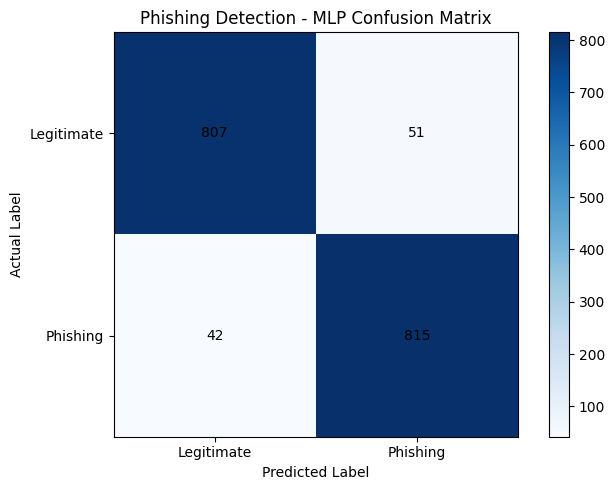

[[807  51]
 [ 42 815]]


In [21]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap="Blues")

plt.title("Phishing Detection - MLP Confusion Matrix")

plt.colorbar()

plt.xticks(
    [0, 1],
    ["Legitimate", "Phishing"]
)

plt.yticks(
    [0, 1],
    ["Legitimate", "Phishing"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

print(cm)

In [22]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "MLP": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100,
        roc_auc * 100
    ]
})

display(results.round(2))

results.to_csv(
    "phishing_mlp_results.csv",
    index=False
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": X_train.shape[1],
        "hidden_1": 64,
        "hidden_2": 32,
        "threshold": 0.5
    },
    "phishing_best_model.pth"
)

joblib.dump(scaler, "phishing_scaler.pkl")
joblib.dump(imputer, "phishing_imputer.pkl")
joblib.dump(feature_names, "phishing_feature_names.pkl")

pd.DataFrame(history).to_csv(
    "phishing_mlp_training_history.csv",
    index=False
)

print("All results and model files saved successfully!")

,Metric,MLP
0,Accuracy,94.58
1,Precision,94.11
2,Recall,95.10
3,F1-Score,94.60
4,ROC-AUC,98.69


All results and model files saved successfully!
